In [7]:
from sound_simulation import *
from beamforming import *
from sensor_array import *
from scene import *
from util import *
from psd_estimation import *
from plot_utils import *
from cropac import *

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, Audio

In [8]:
fig_width = 11

duration = 100
sr = 48000
c = 344
fmin = 500
fmax = 6000
N = 2**10
step = N//2
window = np.hanning(N)
SNR = -8

np.random.seed(42)

sensor_array = array_circle8()
m = sensor_array.positions.shape[1]

noise = create_diffuse_noise(duration * sr, sensor_array.positions, sr)

target_position = np.array([1, 0, 0])
scene = scene_stationary(duration, sr, target_position)
target_sound = np.random.randn(duration*sr)
target_sound = fftwin_filt(target_sound, design_bump_filter(sr, 3000, 300, N))
target_sound = prepare_planewave_audio(scene, sensor_array, (target_sound, sr), duration, sr, db2lin(SNR), False)

audio = noise + target_sound

VN, f, validf = valid_frequency_bins(fmin, fmax, N, sr)
SN, tidx, snaps = stft(audio, window, step, validf)
_, _, target_snaps = stft(target_sound, window, step, validf)
_, _, noise_snaps = stft(noise, window, step, validf)
k = 2 * np.pi * f / c

target_udir = target_position / np.linalg.norm(target_position)
target_steer = create_steering_vectors(create_distance_vectors(target_udir[None,:], sensor_array.positions), k[:,None])

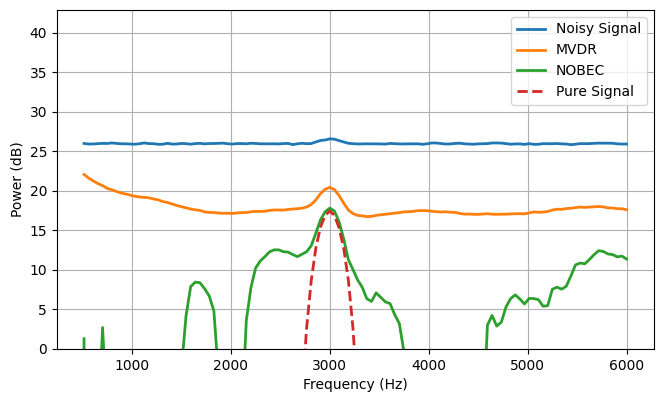

In [9]:
def abs_psd(w1, Sx, w2):
    return np.abs(np.real(np.conj(w1[...,None,:]) @ Sx @ w2[...,:,None])[:,0,0])

class DOBEC_PSDE(PSDEstimator):
    def __init__(self, params: PSDEParams):
        self.update_parameters(params)
    def update_parameters(self, params: PSDEParams):
        Rd = diffuse_covariance_matrices(params.sensor_postions, params.k)
        self.w1 = blended_ch_das_weights(params.target_direction, 1, params.sensor_postions, params.k)
        self.w2 = optimal_secondary_weights(self.w1, params.steering_vectors, [Rd])
    def estimate_psd(self, covariance_matrices):
        return abs_psd(self.w1, covariance_matrices, self.w2)

Sx = total_time_average(np.array([compute_covariance_matrices(snap) for snap in snaps]))
St = total_time_average(np.array([compute_covariance_matrices(snap) for snap in target_snaps]))
Sn = total_time_average(np.array([compute_covariance_matrices(snap) for snap in noise_snaps]))

params = PSDEParams(
    sensor_array.positions,
    target_udir, k,
    target_steer, Sx)
ch0_estimator = CH0_PSDE(params)
mvdr_estimator = MVDR_PSDE(params, 10)
nobec_estimator = NOBEC_PSDE(params, 10)

nobec_psd = nobec_estimator.estimate_psd(Sx)
noisy_psd = ch0_estimator.estimate_psd(Sx)
pure_psd = ch0_estimator.estimate_psd(St)
mvdr_psd = mvdr_estimator.estimate_psd(Sx)

fig = plt.figure(figsize=(fig_width*0.7, fig_width*0.4))
ax = fig.add_subplot(111)
ax.plot(f, pow2db(noisy_psd), label="Noisy Signal", lw=2)
ax.plot(f, pow2db(mvdr_psd), label="MVDR", lw=2)
ax.plot(f, pow2db(nobec_psd), label="NOBEC", lw=2)
ax.plot(f, pow2db(pure_psd), label="Pure Signal", ls="--", lw=2)
ax.grid()
ax.set_ylim(0)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (dB)")

plt.legend()
plt.show()

